# PROJET F16 – LOI D'OKUN

**Étude de la relation entre la croissance économique et le chômage aux États-Unis**

- **Étudiant :** Bakary Traoré
- **Code Apogée :** 26006200
- **Groupe :** FIN G3
- **Pays étudié :** États-Unis
- **Source des données :** FRED – Federal Reserve Bank of St. Louis
- **Environnement :** Python / Google Colab

---

## 1. Sujet et problématique

### Intérêt du sujet

La relation entre la croissance économique et le chômage constitue un enjeu important de la politique économique. La Loi d'Okun permet d'étudier le lien entre l'évolution de l'activité économique et celle du chômage.

### Problématique

Dans quelle mesure la croissance économique suffit-elle à réduire durablement le chômage aux États-Unis ?

### Objectif du projet

Étudier la relation statistique entre la croissance trimestrielle du PIB réel et la variation trimestrielle du taux de chômage aux États-Unis, puis examiner la stabilité de cette relation dans le temps.

### Nature du problème

Régression supervisée : expliquer la variation du taux de chômage à partir de la croissance du PIB réel, au moyen d'une régression linéaire simple.

## 2. Jeu de données

### 2.1. Sources des données

Les données utilisées dans cette étude proviennent de FRED (Federal Reserve Bank of St. Louis).

Deux séries économiques sont exploitées :

- **GDPC1 :** produit intérieur brut réel des États-Unis, à fréquence trimestrielle.
- **UNRATE :** taux de chômage des États-Unis, à fréquence mensuelle.

### 2.2. Période d'étude

L'étude couvre la période allant du premier trimestre 1990 au troisième trimestre 2026, selon les observations disponibles dans les fichiers téléchargés.

### 2.3. Variables utilisées

| Variable | Description | Unité |
|---|---|---|
| GDPC1 | PIB réel | Milliards de dollars chaînés |
| UNRATE | Taux de chômage | Pourcentage |
| GDP_Growth | Croissance trimestrielle annualisée du PIB réel | Pourcentage |
| Delta_UNRATE | Variation trimestrielle du taux de chômage | Points de pourcentage |

### 2.4. Qualité et limites initiales des données

Les deux séries présentent des fréquences différentes : le PIB est trimestriel tandis que le taux de chômage est mensuel.

Une agrégation du chômage par moyenne trimestrielle est donc nécessaire.

Une valeur manquante a été identifiée pour octobre 2025. Le quatrième trimestre 2025 sera considéré comme incomplet et ne sera pas utilisé pour calculer la variation trimestrielle du chômage.

In [ ]:

from pathlib import Path

# Rechercher les fichiers CSV importés dans Colab
fichiers_csv = list(Path("/content").glob("*.csv"))

# Afficher les noms des fichiers trouvés
for fichier in fichiers_csv:
    print(fichier.name)


TAUX DE CHOMAGE DE USA mensuel.csv
PIB REEL USA trimestriel.csv


In [ ]:

import pandas as pd

# Charger les deux fichiers CSV
chomage = pd.read_csv("/content/TAUX DE CHOMAGE DE USA mensuel.csv")
pib = pd.read_csv("/content/PIB REEL USA trimestriel.csv")

# Afficher les cinq premières observations
print("TAUX DE CHÔMAGE")
display(chomage.head())

print("PIB RÉEL")
display(pib.head())


TAUX DE CHÔMAGE


,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5


PIB RÉEL


,observation_date,GDPC1
0,1947-01-01,2182.681
1,1947-04-01,2176.892
2,1947-07-01,2172.432
3,1947-10-01,2206.452
4,1948-01-01,2239.682


In [ ]:

# Convertir les dates au format datetime
chomage["observation_date"] = pd.to_datetime(chomage["observation_date"])
pib["observation_date"] = pd.to_datetime(pib["observation_date"])

# Vérifier les dimensions des deux tableaux
print("DIMENSIONS DES DONNÉES")
print("Chômage :", chomage.shape)
print("PIB :", pib.shape)

# Vérifier les périodes disponibles
print("\nPÉRIODES COUVERTES")
print("Chômage :", chomage["observation_date"].min(),
      "à", chomage["observation_date"].max())
print("PIB :", pib["observation_date"].min(),
      "à", pib["observation_date"].max())

# Vérifier les valeurs manquantes
print("\nVALEURS MANQUANTES")
print(chomage.isna().sum())
print(pib.isna().sum())

# Vérifier les types de données
print("\nTYPES DE DONNÉES")
print(chomage.dtypes)
print(pib.dtypes)


DIMENSIONS DES DONNÉES
Chômage : (946, 2)
PIB : (319, 2)

PÉRIODES COUVERTES
Chômage : 1948-01-01 00:00:00 à 2026-10-01 00:00:00
PIB : 1947-01-01 00:00:00 à 2026-07-01 00:00:00

VALEURS MANQUANTES
observation_date    0
UNRATE              1
dtype: int64
observation_date    0
GDPC1               0
dtype: int64

TYPES DE DONNÉES
observation_date    datetime64[ns]
UNRATE                     float64
dtype: object
observation_date    datetime64[ns]
GDPC1                      float64
dtype: object


In [ ]:

# Examiner les premières valeurs du PIB
print("Premières valeurs du PIB :")
print(pib["GDPC1"].head(10).tolist())

# Examiner le format des valeurs
print("\nType de la première valeur :")
print(type(pib["GDPC1"].iloc[0]))

# Identifier les valeurs qui ne sont pas numériques
pib_test = pd.to_numeric(pib["GDPC1"], errors="coerce")

print("\nNombre de valeurs devenues manquantes après conversion :")
print(pib_test.isna().sum())


Premières valeurs du PIB :
[2182.681, 2176.892, 2172.432, 2206.452, 2239.682, 2276.69, 2289.77, 2292.364, 2260.807, 2253.128]

Type de la première valeur :
<class 'numpy.float64'>

Nombre de valeurs devenues manquantes après conversion :
0


In [ ]:

# Convertir la colonne du PIB en valeurs numériques
pib["GDPC1"] = pd.to_numeric(pib["GDPC1"])

# Vérifier les types après conversion
print("Types des colonnes du PIB :")
print(pib.dtypes)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(pib.isna().sum())


Types des colonnes du PIB :
observation_date    datetime64[ns]
GDPC1                      float64
dtype: object

Valeurs manquantes :
observation_date    0
GDPC1               0
dtype: int64


In [ ]:

# Définir les bornes de la période d'étude
date_debut = "1990-01-01"
date_fin = "2026-09-30"

# Créer des copies limitées à la période choisie
chomage_1990 = chomage[
    (chomage["observation_date"] >= date_debut) &
    (chomage["observation_date"] <= date_fin)
].copy()

pib_1990 = pib[
    (pib["observation_date"] >= date_debut) &
    (pib["observation_date"] <= date_fin)
].copy()

# Vérifier les dimensions
print("Nombre d'observations après sélection :")
print("Chômage :", chomage_1990.shape)
print("PIB :", pib_1990.shape)

# Vérifier les dates
print("\nPériode du chômage :")
print(chomage_1990["observation_date"].min(),
      "à", chomage_1990["observation_date"].max())

print("\nPériode du PIB :")
print(pib_1990["observation_date"].min(),
      "à", pib_1990["observation_date"].max())


Nombre d'observations après sélection :
Chômage : (441, 2)
PIB : (147, 2)

Période du chômage :
1990-01-01 00:00:00 à 2026-09-01 00:00:00

Période du PIB :
1990-01-01 00:00:00 à 2026-07-01 00:00:00


Transformer le chômage mensuel en chômage trimestriel

In [ ]:

# Identifier le trimestre de chaque observation mensuelle
chomage_1990["trimestre"] = (
    chomage_1990["observation_date"].dt.to_period("Q")
)

# Calculer le nombre de mois disponibles et la moyenne trimestrielle
chomage_trimestriel = (
    chomage_1990.groupby("trimestre")
    .agg(
        nb_mois=("UNRATE", "count"),
        taux_chomage=("UNRATE", "mean")
    )
    .reset_index()
)

# Ne conserver la moyenne que si les trois mois sont disponibles
chomage_trimestriel.loc[
    chomage_trimestriel["nb_mois"] < 3,
    "taux_chomage"
] = pd.NA

# Afficher les résultats
print("Nombre de trimestres :", len(chomage_trimestriel))

print("\nTrimestres incomplets :")
display(
    chomage_trimestriel[
        chomage_trimestriel["nb_mois"] < 3
    ]
)

print("\nPremières observations trimestrielles :")
display(chomage_trimestriel.head())


Nombre de trimestres : 147

Trimestres incomplets :


,trimestre,nb_mois,taux_chomage
143,2025Q4,2,NaN



Premières observations trimestrielles :


,trimestre,nb_mois,taux_chomage
0,1990Q1,3,5.300000
1,1990Q2,3,5.333333
2,1990Q3,3,5.700000
3,1990Q4,3,6.133333
4,1991Q1,3,6.600000


Préparer la fusion des deux séries

In [ ]:

# Créer une variable trimestrielle pour le PIB
pib_1990["trimestre"] = (
    pib_1990["observation_date"].dt.to_period("Q")
)

# Renommer la colonne du PIB
pib_1990 = pib_1990.rename(
    columns={"GDPC1": "PIB_reel"}
)

# Fusionner les deux séries sur le trimestre
donnees = pd.merge(
    pib_1990[["trimestre", "PIB_reel"]],
    chomage_trimestriel[
        ["trimestre", "taux_chomage"]
    ],
    on="trimestre",
    how="inner"
)

# Trier les observations chronologiquement
donnees = donnees.sort_values("trimestre").reset_index(drop=True)

# Afficher les résultats
print("Dimensions du tableau fusionné :", donnees.shape)

print("\nPremières observations :")
display(donnees.head())

print("\nDernières observations :")
display(donnees.tail())

print("\nValeurs manquantes :")
print(donnees.isna().sum())


Dimensions du tableau fusionné : (147, 3)

Premières observations :


,trimestre,PIB_reel,taux_chomage
0,1990Q1,10047.386,5.300000
1,1990Q2,10083.855,5.333333
2,1990Q3,10090.569,5.700000
3,1990Q4,9998.704,6.133333
4,1991Q1,9951.916,6.600000



Dernières observations :


,trimestre,PIB_reel,taux_chomage
142,2025Q3,24112.966,4.333333
143,2025Q4,24125.479,NaN
144,2026Q1,24274.383,4.333333
145,2026Q2,24408.011,4.266667
146,2026Q3,24611.077,4.133333



Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    1
dtype: int64


**Calculer les deux variables économiques**

Pour étudier la loi d'Okun, nous avons besoin de deux nouvelles variables :
1. La croissance trimestrielle annualisée du PIB réel.
2. La variation trimestrielle du taux de chômage, exprimée en points de pourcentage.

In [ ]:

# Calculer la croissance trimestrielle annualisée du PIB
donnees["GDP_Growth"] = (
    ((donnees["PIB_reel"] / donnees["PIB_reel"].shift(1))**4 - 1) * 100
)

# Calculer la variation trimestrielle du chômage
donnees["Delta_UNRATE"] = donnees["taux_chomage"].diff()

# Afficher les premières observations
print("Premières observations après calcul :")
display(donnees.head(10))

# Afficher les observations autour de 2025
print("\nObservations autour de 2025 :")
display(donnees.iloc[138:147])

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees.isna().sum())


Premières observations après calcul :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
0,1990Q1,10047.386,5.300000,NaN,NaN
1,1990Q2,10083.855,5.333333,1.459804,0.033333
2,1990Q3,10090.569,5.700000,0.266593,0.366667
3,1990Q4,9998.704,6.133333,-3.592189,0.433333
4,1991Q1,9951.916,6.600000,-1.858665,0.466667
5,1991Q2,10029.510,6.833333,3.155421,0.233333
6,1991Q3,10080.195,6.866667,2.036810,0.033333
7,1991Q4,10115.329,7.100000,1.401485,0.233333
8,1992Q1,10236.435,7.366667,4.875702,0.266667
9,1992Q2,10347.429,7.600000,4.408267,0.233333



Observations autour de 2025 :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
138,2024Q3,23501.760,4.166667,3.152997,2.000000e-01
139,2024Q4,23641.759,4.133333,2.404159,-3.333333e-02
140,2025Q1,23650.213,4.133333,0.143112,8.881784e-16
141,2025Q2,23884.563,4.200000,4.022904,6.666667e-02
142,2025Q3,24112.966,4.333333,3.880334,1.333333e-01
143,2025Q4,24125.479,NaN,0.207735,NaN
144,2026Q1,24274.383,4.333333,2.491776,NaN
145,2026Q2,24408.011,4.266667,2.220208,-6.666667e-02
146,2026Q3,24611.077,4.133333,3.369619,-1.333333e-01



Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    1
GDP_Growth      1
Delta_UNRATE    3
dtype: int64


**Construire le jeu de données final**

In [ ]:

# Créer le jeu de données final
donnees_finales = donnees.dropna(
    subset=["GDP_Growth", "Delta_UNRATE"]
).copy()

# Vérifier les dimensions
print("Dimensions du jeu de données final :")
print(donnees_finales.shape)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees_finales.isna().sum())

# Afficher les premières et dernières observations
print("\nPremières observations :")
display(donnees_finales.head())

print("\nDernières observations :")
display(donnees_finales.tail())


Dimensions du jeu de données final :
(144, 5)

Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    0
GDP_Growth      0
Delta_UNRATE    0
dtype: int64

Premières observations :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
1,1990Q2,10083.855,5.333333,1.459804,0.033333
2,1990Q3,10090.569,5.700000,0.266593,0.366667
3,1990Q4,9998.704,6.133333,-3.592189,0.433333
4,1991Q1,9951.916,6.600000,-1.858665,0.466667
5,1991Q2,10029.510,6.833333,3.155421,0.233333



Dernières observations :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
140,2025Q1,23650.213,4.133333,0.143112,8.881784e-16
141,2025Q2,23884.563,4.200000,4.022904,6.666667e-02
142,2025Q3,24112.966,4.333333,3.880334,1.333333e-01
145,2026Q2,24408.011,4.266667,2.220208,-6.666667e-02
146,2026Q3,24611.077,4.133333,3.369619,-1.333333e-01


In [ ]:

# Recalculer la croissance trimestrielle non annualisée du PIB
donnees["GDP_Growth"] = (
    (donnees["PIB_reel"] / donnees["PIB_reel"].shift(1) - 1) * 100
)

# La variation trimestrielle du chômage reste inchangée
donnees["Delta_UNRATE"] = donnees["taux_chomage"].diff()

# Reconstruire le jeu de données final
donnees_finales = donnees.dropna(
    subset=["GDP_Growth", "Delta_UNRATE"]
).copy()

# Afficher les résultats
display(donnees_finales.head())

print("Dimensions :", donnees_finales.shape)


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
1,1990Q2,10083.855,5.333333,0.362970,0.033333
2,1990Q3,10090.569,5.700000,0.066582,0.366667
3,1990Q4,9998.704,6.133333,-0.910405,0.433333
4,1991Q1,9951.916,6.600000,-0.467941,0.466667
5,1991Q2,10029.510,6.833333,0.779689,0.233333


Dimensions : (144, 5)


**Contrôle final**

In [ ]:

# Vérifier l'ordre chronologique
print("Premier trimestre :", donnees_finales["trimestre"].min())
print("Dernier trimestre :", donnees_finales["trimestre"].max())

# Vérifier les doublons
print("\nNombre de doublons :")
print(donnees_finales["trimestre"].duplicated().sum())

# Vérifier les dimensions
print("\nDimensions :", donnees_finales.shape)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees_finales.isna().sum())


Premier trimestre : 1990Q2
Dernier trimestre : 2026Q3

Nombre de doublons :
0

Dimensions : (144, 5)

Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    0
GDP_Growth      0
Delta_UNRATE    0
dtype: int64


In [ ]:

from pathlib import Path

# Créer le dossier des données préparées
dossier = Path("/content/data/processed")
dossier.mkdir(parents=True, exist_ok=True)

# Enregistrer le jeu de données final
chemin = dossier / "donnees_finales_F16.csv"
donnees_finales.to_csv(chemin, index=False)

print("Fichier enregistré :", chemin)
print("Taille du fichier :", donnees_finales.shape)


Fichier enregistré : /content/data/processed/donnees_finales_F16.csv
Taille du fichier : (144, 5)


**Analyse exploratoire des données (EDA)**

In [ ]:
# 1. Importer les bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Afficher les statistiques descriptives
donnees_finales.describe()

,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
count,144.000000,144.000000,144.000000,144.000000
mean,16481.899021,5.665046,0.625460,-0.008102
std,3990.211343,1.739555,1.099190,0.906227
min,9951.916000,3.533333,-7.876784,-4.200000
25%,13398.960250,4.325000,0.361884,-0.200000
50%,16572.288000,5.333333,0.671775,-0.066667
75%,19327.849750,6.608333,0.974412,0.066667
max,24611.077000,13.000000,7.762279,9.166667


**Construire les trois graphiques**

Graphique 1 — Évolution de la croissance du PIB



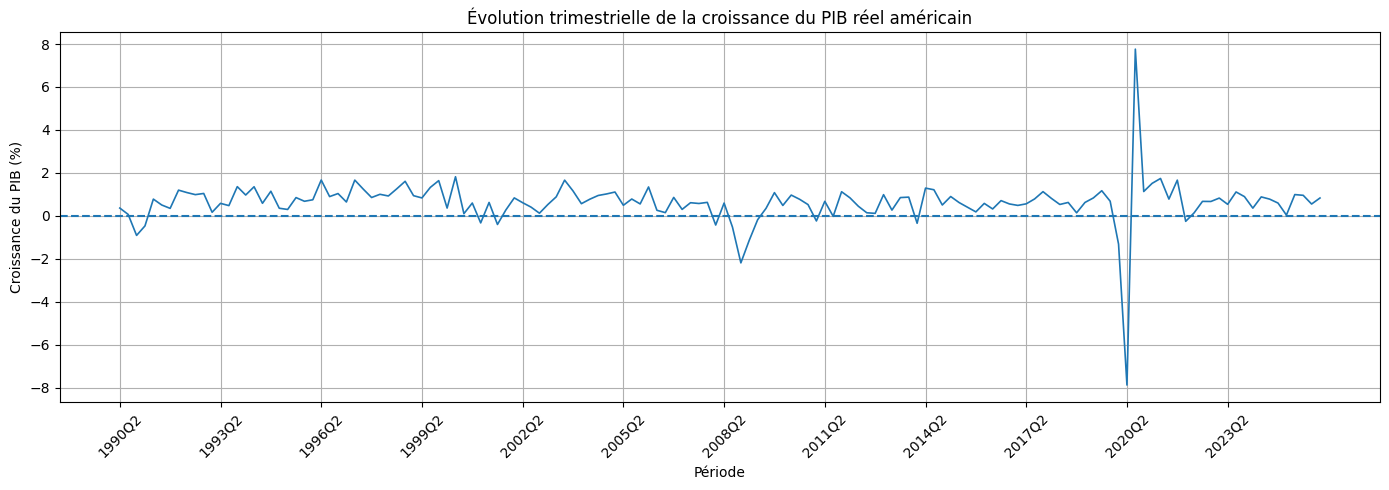

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    range(len(donnees_finales)),
    donnees_finales["GDP_Growth"],
    linewidth=1.2
)

plt.axhline(y=0, linestyle="--")

plt.title("Évolution trimestrielle de la croissance du PIB réel américain")
plt.xlabel("Période")
plt.ylabel("Croissance du PIB (%)")

# Afficher une étiquette tous les 12 trimestres
positions = range(0, len(donnees_finales), 12)
etiquettes = donnees_finales["trimestre"].astype(str)

plt.xticks(
    positions,
    etiquettes.iloc[::12],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

**Interprétation du graphique 1: croissance du PIB américain**

Le graphique présente l'évolution trimestrielle de la croissance du PIB réel américain entre 1990 et 2026. Il montre que la croissance économique est généralement positive, mais qu'elle connaît plusieurs épisodes de contraction. Les variations les plus importantes apparaissent autour de 2020, période marquée par la crise sanitaire liée à la COVID-19. Ces fluctuations illustrent l'instabilité de l'activité économique et permettront d'étudier son association avec les variations du chômage.




**Deuxième graphique — Évolution du taux de chômage américain**

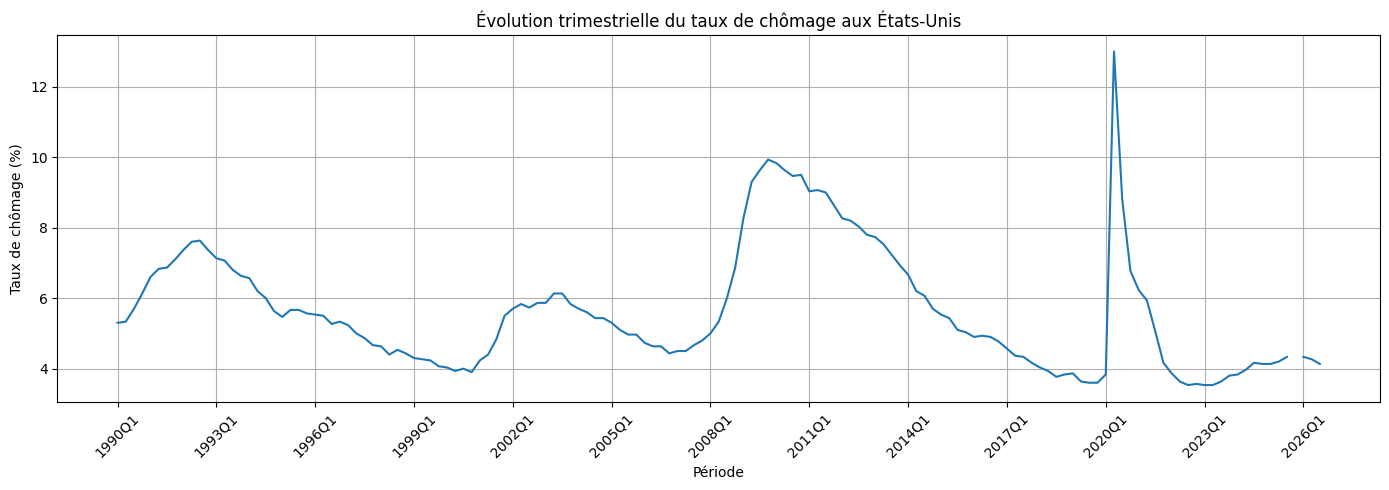

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    range(len(chomage_trimestriel)),
    chomage_trimestriel["taux_chomage"],
    linewidth=1.5
)

plt.title("Évolution trimestrielle du taux de chômage aux États-Unis")
plt.xlabel("Période")
plt.ylabel("Taux de chômage (%)")

# Afficher une date tous les 12 trimestres
positions = range(0, len(chomage_trimestriel), 12)
etiquettes = chomage_trimestriel["trimestre"].astype(str)

plt.xticks(
    positions,
    etiquettes.iloc[::12],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

**Interprétation du graphique 2: taux de chômage américain**

Le graphique présente l'évolution trimestrielle du taux de chômage aux États-Unis entre 1990 et 2026. Il met en évidence plusieurs épisodes de hausse importante du chômage, notamment lors de la crise financière de 2008 et de la crise sanitaire de 2020. Après ces périodes, le taux de chômage diminue progressivement. Ces évolutions montrent que le marché du travail américain est sensible aux fluctuations de l'activité économique.

**Troisième graphique — Relation entre croissance du PIB et variation du chômage**

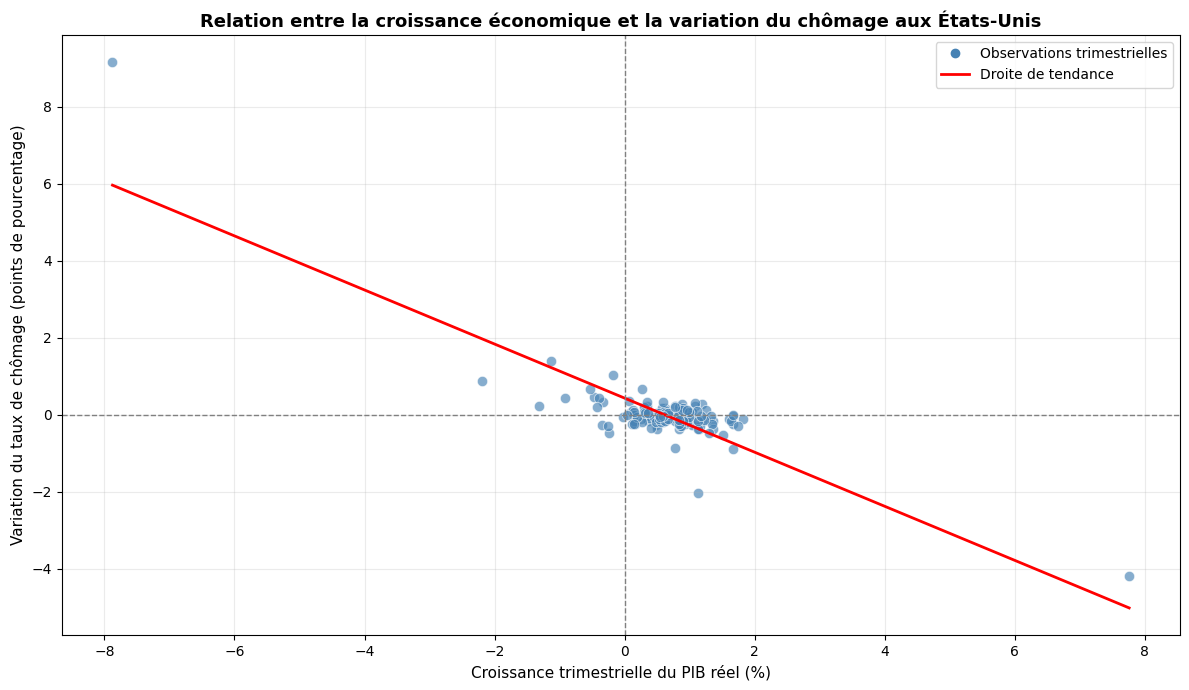

In [ ]:
plt.figure(figsize=(12, 7))

# Nuage de points
sns.scatterplot(
    data=donnees_finales,
    x="GDP_Growth",
    y="Delta_UNRATE",
    label="Observations trimestrielles",
    color="steelblue",
    alpha=0.65,
    s=55
)

# Droite de tendance
sns.regplot(
    data=donnees_finales,
    x="GDP_Growth",
    y="Delta_UNRATE",
    scatter=False,
    ci=None,
    line_kws={
        "color": "red",
        "linewidth": 2,
        "label": "Droite de tendance"
    }
)


# Lignes de référence
plt.axhline(y=0, color="gray", linestyle="--", linewidth=1)
plt.axvline(x=0, color="gray", linestyle="--", linewidth=1)

# Titres et axes
plt.title(
    "Relation entre la croissance économique et la variation du chômage aux États-Unis",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Croissance trimestrielle du PIB réel (%)", fontsize=11)
plt.ylabel("Variation du taux de chômage (points de pourcentage)", fontsize=11)

# Légende
plt.legend(loc="upper right", fontsize=10)

# Présentation
plt.grid(alpha=0.25)
plt.tight_layout()
from matplotlib.lines import Line2D

plt.legend(handles=[
    Line2D([0], [0], marker="o", color="steelblue",
           linestyle="None", label="Observations trimestrielles"),
    Line2D([0], [0], color="red",
           linewidth=2, label="Droite de tendance")
])
plt.show()

**Interprétation économique du graphique 3: Relation entre croissance du PIB et variation du chômage**

Le nuage de points met en évidence une relation linéaire négative entre la croissance trimestrielle du PIB réel et la variation du taux de chômage aux États-Unis. La droite de tendance décroissante suggère que les périodes de croissance économique plus élevée sont généralement associées à une diminution de la variation du chômage. Toutefois, certaines observations atypiques sont éloignées du groupe principal. Cette relation descriptive ne permet pas, à elle seule, de conclure à un lien de causalité.

### Synthèse générale de l'analyse exploratoire
L'analyse exploratoire des données a permis de mieux comprendre l'évolution de la croissance économique et du chômage aux États-Unis sur la période étudiée.

Les statistiques descriptives indiquent que la croissance trimestrielle moyenne du PIB réel est d'environ 0,63 %, tandis que le taux de chômage moyen atteint 5,67 %.

L'analyse graphique révèle plusieurs fluctuations économiques importantes, notamment pendant la crise financière de 2008 et la crise sanitaire de 2020. Ces périodes sont caractérisées par une augmentation significative du chômage et des variations importantes de la croissance économique.

Par ailleurs, le nuage de points met en évidence une relation négative entre la croissance du PIB réel et la variation du taux de chômage. Cette observation est cohérente avec la loi d'Okun.

Enfin, la présence de valeurs extrêmes mérite une attention particulière, car ces observations peuvent influencer l'estimation du modèle de régression linéaire.

Ces premiers résultats justifient la poursuite de l'étude à travers une modélisation statistique afin d'évaluer plus précisément la relation entre la croissance économique et les variations du chômage.

**Préparation du modèle**

**Définition des variables**

Dans notre modèle de la loi d'Okun :
- Variable explicative (X) : GDP_Growth — croissance trimestrielle du PIB réel.
- Variable dépendante (Y) : Delta_UNRATE — variation trimestrielle du taux de chômage.
Nous cherchons à vérifier dans quelle mesure la croissance du PIB est associée à la variation du chômage.

In [ ]:
# Définition de la variable explicative
X = donnees_finales[["GDP_Growth"]]

# Définition de la variable dépendante
y = donnees_finales["Delta_UNRATE"]

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Afficher les premières observations
display(X.head())
display(y.head())

Dimensions de X : (144, 1)
Dimensions de y : (144,)


,GDP_Growth
1,0.362970
2,0.066582
3,-0.910405
4,-0.467941
5,0.779689


,Delta_UNRATE
1,0.033333
2,0.366667
3,0.433333
4,0.466667
5,0.233333


**Séparation des données : entraînement et test**

80 % des observations pour
l'entraînement du modèle.

20 % des observations pour le test du modèle.

In [ ]:
from sklearn.model_selection import train_test_split

# Séparation chronologique des données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

# Vérification des dimensions
print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)

print("Observations d'entraînement :", len(y_train))
print("Observations de test :", len(y_test))

Données d'entraînement : (115, 1)
Données de test : (29, 1)
Observations d'entraînement : 115
Observations de test : 29


**Prochaine étape : construire le modèle de régression linéaire**


In [ ]:
# Importer l'algorithme de régression linéaire
from sklearn.linear_model import LinearRegression

# Créer le modèle
modele = LinearRegression()

# Entraîner le modèle
modele.fit(X_train, y_train)

# Afficher les coefficients
print("Constante (β0) :", modele.intercept_)
print("Coefficient de croissance (β1) :", modele.coef_[0])

Constante (β0) : 0.15202144159756895
Coefficient de croissance (β1) : -0.26775831142142753


**Interprétation économique**

Le modèle de régression linéaire simple a été entraîné sur 115 observations. Le coefficient associé à la croissance du PIB est négatif (-0,2678), ce qui indique une relation inverse entre la croissance économique et la variation du taux de chômage. La constante est estimée à 0,1520. Ces résultats sont cohérents avec la relation théorique proposée par la loi d'Okun.

**évaluer le modèle**


Nous allons maintenant mesurer la qualité des prédictions sur les 29 observations de test, à l'aide de trois indicateurs :
- MAE : erreur absolue moyenne.
- MSE : erreur quadratique moyenne.
- \(R^2\) : coefficient de détermination.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur les données de test
y_pred = modele.predict(X_test)

# Calcul des indicateurs
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Affichage des résultats
print("MAE :", mae)
print("MSE :", mse)
print("R² :", r2)

MAE : 0.5576912751188571
MSE : 2.013057687733634
R² : 0.46017986270499434


### Évaluation des performances du modèle

L'évaluation du modèle sur les 29 observations de test donne une MAE de 0,5577 et une MSE de 2,0131. Ces résultats indiquent que les prédictions présentent des écarts avec les valeurs réellement observées.

Le coefficient de détermination R² est de 0,4602, ce qui signifie que le modèle explique environ 46,02 % de la variation de la variable dépendante sur l'échantillon de test.

Ces résultats montrent que la croissance du PIB possède un pouvoir explicatif sur les variations du chômage, mais que d'autres facteurs économiques interviennent également. Le modèle constitue donc une première approximation de la relation décrite par la loi d'Okun.

**Comparaison des valeurs réelles et prédites**

*   Les valeurs réellement observées de Delta_UNRATE.

*   Les valeurs prédites par notre modèle de régression linéaire.


**#  Construire le graphique**

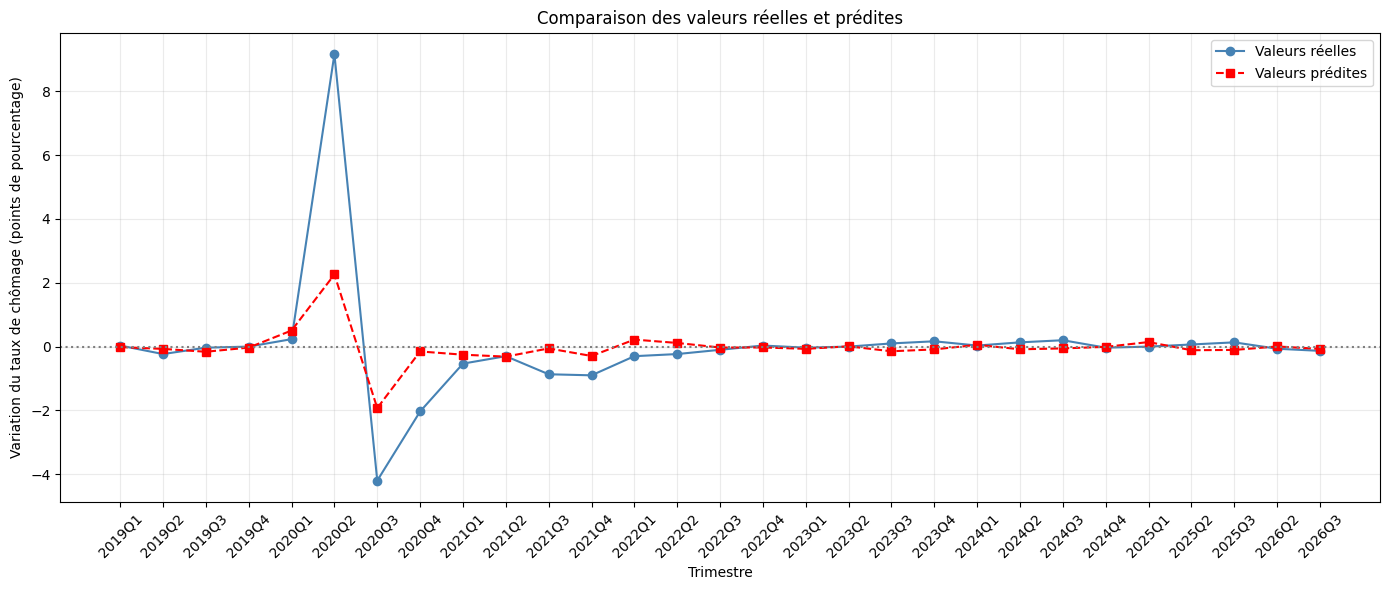

In [ ]:
plt.figure(figsize=(14, 6))

# Récupérer les trimestres correspondant aux données de test
periodes_test = donnees_finales.loc[y_test.index, "trimestre"].astype(str)

# Valeurs réelles
plt.plot(
    periodes_test,
    y_test,
    label="Valeurs réelles",
    color="steelblue",
    marker="o",
    linewidth=1.5
)

# Valeurs prédites
plt.plot(
    periodes_test,
    y_pred,
    label="Valeurs prédites",
    color="red",
    marker="s",
    linestyle="--",
    linewidth=1.5
)

plt.title("Comparaison des valeurs réelles et prédites")
plt.xlabel("Trimestre")
plt.ylabel("Variation du taux de chômage (points de pourcentage)")

plt.xticks(rotation=45)
plt.axhline(y=0, color="gray", linestyle=":")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Comparaison des valeurs réelles et prédites

La comparaison des valeurs réelles et prédites montre que le modèle reproduit relativement bien certaines variations modérées du taux de chômage, notamment entre 2021 et 2026.

Cependant, des écarts importants apparaissent pendant la crise sanitaire de 2020. Le modèle sous-estime notamment la forte augmentation du chômage, puis sa diminution au trimestre suivant.

Ces résultats montrent que la régression linéaire simple présente des limites dans la représentation des fluctuations économiques exceptionnelles. La croissance du PIB constitue un facteur explicatif important, mais elle ne suffit pas à représenter toute la complexité du marché du travail.

**Analyse critique du modèle**

In [ ]:
# Créer un tableau de comparaison
comparaison = pd.DataFrame({
    "Trimestre": donnees_finales.loc[y_test.index, "trimestre"].astype(str),
    "Valeur_reelle": y_test,
    "Valeur_predite": y_pred
})

# Calculer les erreurs
comparaison["Erreur"] = (
    comparaison["Valeur_reelle"] - comparaison["Valeur_predite"]
)

comparaison["Erreur_absolue"] = comparaison["Erreur"].abs()

# Afficher les 10 plus grandes erreurs
top_erreurs = comparaison.sort_values(
    by="Erreur_absolue",
    ascending=False
).head(10)

display(top_erreurs)

,Trimestre,Valeur_reelle,Valeur_predite,Erreur,Erreur_absolue
121,2020Q2,9.166667,2.261096,6.905571,6.905571
122,2020Q3,-4.200000,-1.926393,-2.273607,2.273607
123,2020Q4,-2.033333,-0.151487,-1.881847,1.881847
126,2021Q3,-0.866667,-0.056951,-0.809715,0.809715
127,2021Q4,-0.900000,-0.293344,-0.606656,0.606656
128,2022Q1,-0.300000,0.220122,-0.520122,0.520122
129,2022Q2,-0.233333,0.114674,-0.348008,0.348008
124,2021Q1,-0.533333,-0.253252,-0.280082,0.280082
120,2020Q1,0.233333,0.504478,-0.271144,0.271144
138,2024Q3,0.200000,-0.056588,0.256588,0.256588


### Analyse des erreurs de prédiction et des observations extrêmes

L'examen des dix plus grandes erreurs de prédiction révèle que les écarts les plus importants se concentrent principalement autour de l'année 2020.

Le trimestre 2020Q2 présente l'erreur absolue la plus élevée, avec environ 6,91 points de pourcentage. Le modèle prédit une augmentation du chômage de 2,26 points, alors que la variation réellement observée atteint 9,17 points.

Des écarts importants apparaissent également en 2020Q3 et 2020Q4. Ces résultats montrent que le modèle a des difficultés à représenter les fluctuations exceptionnelles du marché du travail pendant la crise sanitaire.

Ces observations appartiennent à l'échantillon de test et n'ont donc pas participé à l'estimation initiale des coefficients. Elles mettent néanmoins en évidence les limites prédictives du modèle face aux événements économiques exceptionnels.

**Vérification de la significativité statistique**

**Effectuer un test statistique**

In [ ]:
import statsmodels.api as sm

# Ajouter une constante au modèle
X_train_stats = sm.add_constant(X_train)

# Estimer la régression OLS
modele_ols = sm.OLS(y_train, X_train_stats).fit()

# Afficher les résultats statistiques
print(modele_ols.summary())

                            OLS Regression Results                            
Dep. Variable:           Delta_UNRATE   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.302
Method:                 Least Squares   F-statistic:                     50.27
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           1.23e-10
Time:                        07:37:09   Log-Likelihood:                 2.7074
No. Observations:                 115   AIC:                            -1.415
Df Residuals:                     113   BIC:                             4.075
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1520      0.032      4.727      0.0

**Vérifier l'autocorrélation des résidus**

In [ ]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Test de Breusch-Godfrey avec 4 retards trimestriels
bg_test = acorr_breusch_godfrey(modele_ols, nlags=4)

print("Statistique LM :", bg_test[0])
print("P-value LM :", bg_test[1])
print("Statistique F :", bg_test[2])
print("P-value F :", bg_test[3])

Statistique LM : 32.687016397856226
P-value LM : 1.3843360358616174e-06
Statistique F : 10.821150660105378
P-value F : 2.0055535202891208e-07


/tmp/ipykernel_1424/3442837168.py:4: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(modele_ols, nlags=4)


## 9. Conclusion générale

Cette étude met en évidence une relation négative entre la croissance trimestrielle du PIB réel et la variation du taux de chômage aux États-Unis. Le coefficient estimé de la croissance est de -0,2678, ce qui est cohérent avec la loi d'Okun. Toutefois, le modèle explique environ 46,02 % des variations du chômage sur l'échantillon de test, ce qui montre que la croissance économique ne suffit pas, à elle seule, à expliquer l'évolution du chômage. Les difficultés de prédiction observées pendant la crise sanitaire de 2020 ainsi que l'autocorrélation des résidus constituent des limites importantes de cette étude.

## 10. Références et reproduction

### 10.1 Sources des données

Les données utilisées dans cette étude proviennent de la base **FRED (Federal Reserve Economic Data)** de la Federal Reserve Bank of St. Louis.

- **PIB réel des États-Unis (GDPC1)** : https://fred.stlouisfed.org/series/GDPC1
- **Taux de chômage américain (UNRATE)** : https://fred.stlouisfed.org/series/UNRATE

Les deux séries ont été utilisées pour étudier la relation entre la croissance économique et la variation du chômage aux États-Unis sur la période retenue.

**Date d'extraction des données :** [à compléter avec la date réelle de téléchargement].

### 10.2 Ressources méthodologiques

- Documentation officielle de pandas : https://pandas.pydata.org/docs/
- Documentation officielle de scikit-learn : https://scikit-learn.org/stable/
- Documentation officielle de statsmodels : https://www.statsmodels.org/stable/

### 10.3 Dépôt GitHub

Le code source, les données préparées et les documents du projet sont disponibles ici :

https://github.com/bakary289/26006200-BAKARY-TRAORE-FIN-G3

### 10.4 Reproduction des résultats

Pour reproduire les résultats de cette étude :

1. Cloner ou télécharger le dépôt GitHub.
2. Installer les bibliothèques nécessaires à partir du fichier `requirements.txt`.
3. Ouvrir le notebook du projet dans Google Colab ou Jupyter.
4. Vérifier la présence des fichiers de données dans les dossiers prévus.
5. Exécuter le notebook dans l'ordre, de la première à la dernière cellule.

Les résultats présentés dans le compte rendu sont issus de l'exécution du notebook Python.